## 선형회귀 실습

### 학습 데이터 준비

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
# 선형회귀 모델 임포트
from sklearn.linear_model import LinearRegression

# 한글 폰트 설정
plt.rcParams["font.family"] = "Malgun Gothic"

# 데이터
data = {
    "hours": [1, 2, 3, 4, 5],
    "scores": [47, 53, 65, 73, 87]
}

# 판다스 데이터 프레임으로 전환
df = pd.DataFrame(data)
df

,hours,scores
0,1,47
1,2,53
2,3,65
3,4,73
4,5,87


### 입력 데이터와 정답 데이터 분리

In [2]:
# 입력 데이터 (피쳐: Feature)
X = df[["hours"]]   # 공부시간

# 출력 데이터 (Target) : 1차원 - 정답 : 종속변수
y = df["scores"]    # 시험점수

### 모델 생성 및 학습

In [3]:
# 선형회귀 모델 객체 생성
model = LinearRegression()
# 모델 학습
model.fit(X, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[10.]
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](1,)",['hours']
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,35
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)


### 결과 확인

In [4]:
# 다중 선형회귀의 경우 결과값이 배열로 리턴
# 기울기는 배열 리턴
print(f"기울기: {model.coef_[0]:.2f}")  # 기울기 Weight  
print(f"절편: {model.intercept_:.2f}")  # 절편 Bias

기울기: 10.00
절편: 35.00


### 새로운 데이터로 예측하기

In [5]:
# 6시간 학습한 학생의 성적 예측
new_data = pd.DataFrame({"hours": [6]}) # X 독립변수 1개 추가

predicted_score = model.predict(new_data)
print(f"6시간 학습한 학생의 예상성적: {predicted_score[0]:.2f}점")

6시간 학습한 학생의 예상성적: 95.00점


### 학습 결과 시각화

학습 데이터에 대한 예측값: [45. 55. 65. 75. 85.]


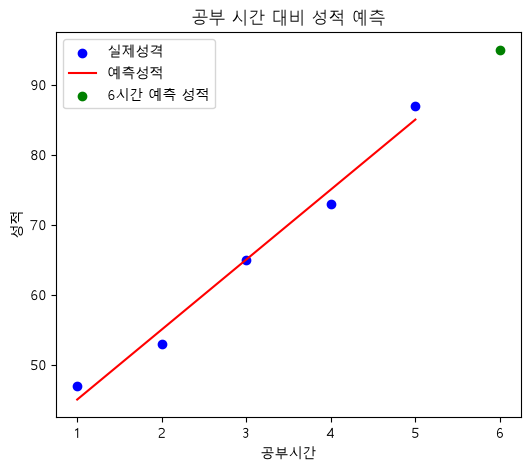

In [6]:
# 학습 데이터에 대한 예측값
y_pred = model.predict(X)
print("학습 데이터에 대한 예측값:", y_pred)

plt.figure(figsize=(6, 5))

# 실제 성적 (산점도)
plt.scatter(X["hours"], y, color="blue", label="실제성격")

# 예측한 성적 (회귀직선)
plt.plot(X["hours"], y_pred, color="red", label="예측성적")

# 6시간 학습한 학생의 예측 성적
plt.scatter(6, predicted_score[0], color="green", label="6시간 예측 성적")

plt.title("공부 시간 대비 성적 예측")
plt.xlabel("공부시간")
plt.ylabel("성적")
plt.legend()
plt.show()

### 모델 평가

In [7]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# MAE : 오차 절대 평균
# 오차의 크기를 직관적으로 이해
mae = mean_absolute_error(y, y_pred)
print(f"학습데이터에 대한 평균 절대 오차(MAE: {mae:.2f})")

# MSE : 오차 제곱 평균
# 제곱하는 이유는 큰 오차에 대해서 민감하게 반응
mse = mean_squared_error(y, y_pred)
print(f"학습데이터에 대한 평균 제곱 오차(MSE: {mse:.2f})")

# R2 Score : 결정계수
# 모델이 실제 데이러틀 얼마만큼 정확한지를 나타내는 지표
# 0 <==> 1
# 음수일 경우 학습 실패
r2 = r2_score(y, y_pred)
print(f"학습데이터에 대한 결절계수(R^2): {r2:.2f})")


학습데이터에 대한 평균 절대 오차(MAE: 1.60)
학습데이터에 대한 평균 제곱 오차(MSE: 3.20)
학습데이터에 대한 결절계수(R^2): 0.98)


## 경사하강법 (Gradient Descent)

- 기울기(Weight) : 10
- 절편(Bias)     : 35
- 6시간 학습     : 96점

### 손실 함수 (Loss Function)

- 모델이 예측한 값이 실제 정답과 얼마나 차이가 나는지를 수치로 표현하는 함수
- MSE를 대표적으로 사용

### 학습 데이터 준비

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
# 배치 하강법 (BGD) : 전체 데이터를 사용, 시간, 리소스 많이 사용
# 확률적 경사 하강법 (SGD) : 확률적을 1개의 데이터를 추출해서 하강 방법
from sklearn.linear_model import SGDRegressor
from sklearn.metrics import mean_squared_error

# 학습 데이터 생성
df = pd.DataFrame({
    "hours": [1, 2, 3, 4, 5],
    "scores": [47, 53, 65, 73, 87]
})

# 독립변수 (입력변수: Feature)
X = df[["hours"]]
# 종속변수 (정답 : Target)
y = df["scores"]

df

,hours,scores
0,1,47
1,2,53
2,3,65
3,4,73
4,5,87


In [9]:
# 선형회귀
model = LinearRegression()
# 모델 학습
model.fit(X, y)
# 예측값
y_pred = model.predict(X)
# 결과 값 : 경사하강법으로 도달하려는 목표
print(f"Weight: {model.coef_[0]:.2f}")
print(f"Bias: {model.intercept_:.2f}")
print(f'MSE: {mean_squared_error(y, y_pred):.4f}')

Weight: 10.00
Bias: 35.00
MSE: 3.2000


### 확률적 경사하강법 모델 생성
- SGDRegressor 모델 생성
- SGD(Stochastic Gradient Descent)

In [10]:
sgd = SGDRegressor(
    loss="squared_error",      # 제곱 오차 기반 손실함수
    learning_rate="constant",  # 학습률을 일정하게 유지
    eta0=0.01,                 # 초기 학습률
    max_iter=1000,             # 학습횟수 fit() 반복 회수
    shuffle=False,             # 학습데이터 섞지 않음
    random_state=42            # 난수 시드 설정
)

In [11]:
# 전체 데이터를 기준으로 총 몇회 반복
epochs = 1000

# 학습과정 저장 리스트
history = []

for epoch in range(epochs):
    # 전체 데이터 1회 학습  (1 epoch)
    sgd.partial_fit(X, y)

    # 1회 학습 후 예측
    y_pred = sgd.predict(X)

    # 현재 모델의 MSE 계산
    mse = mean_squared_error(y, y_pred)

    # 현재 학습 결과 저장(누적)
    history.append({
        "epoch": epoch + 1,
        "weight": sgd.coef_[0],
        "bias": sgd.intercept_[0],
        "mse": mse
    })

# 학습 기록 => DataFrame으로 변환
history_df = pd.DataFrame(history)
history_df

,epoch,weight,bias,mse
0,1,8.455225,2.731163,1369.816039
1,2,12.813586,4.270770,515.808449
2,3,15.045308,5.190714,269.417813
3,4,16.173242,5.787904,193.744630
4,5,16.728403,6.216494,167.673523
...,...,...,...,...
995,996,10.129378,34.741070,3.250171
996,997,10.129367,34.741113,3.250168
997,998,10.129357,34.741155,3.250165
998,999,10.129346,34.741197,3.250162


In [12]:
history_df[ history_df["epoch"].isin((1,5,10,50,100,300,500,1000)) ]

,epoch,weight,bias,mse
0,1,8.455225,2.731163,1369.816039
4,5,16.728403,6.216494,167.673523
9,10,17.060518,7.615610,141.377004
49,50,15.031795,15.629821,72.111791
99,100,13.294764,22.401342,32.278720
299,300,10.678818,32.599172,4.254356
499,500,10.223895,34.372614,3.302220
999,1000,10.129335,34.741238,3.250159


### 손실함수 차트

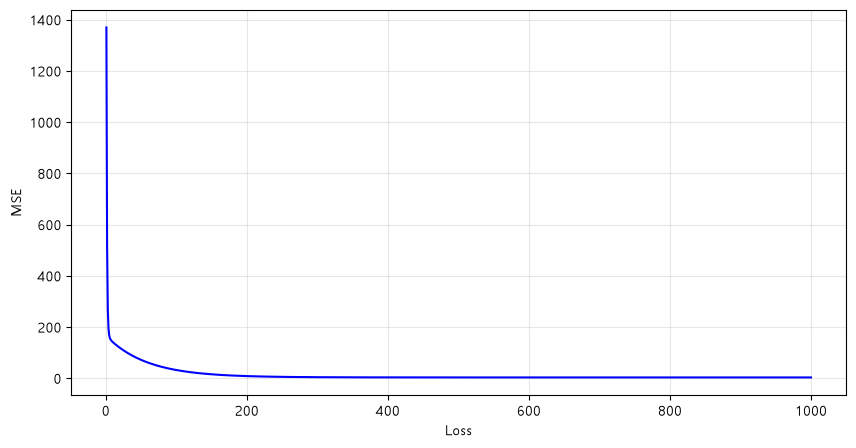

In [15]:
plt.figure(figsize=(10,5))

# Epoch에 따른 MSE 변화
plt.plot(
    history_df["epoch"],
    history_df["mse"],
    color="blue",
    label="학습 손실(Training loss)"
)
plt.xlabel("Loss")
plt.ylabel("MSE")
plt.grid(alpha=0.3)
plt.show()

### 기울기와 절편 변화 시각화

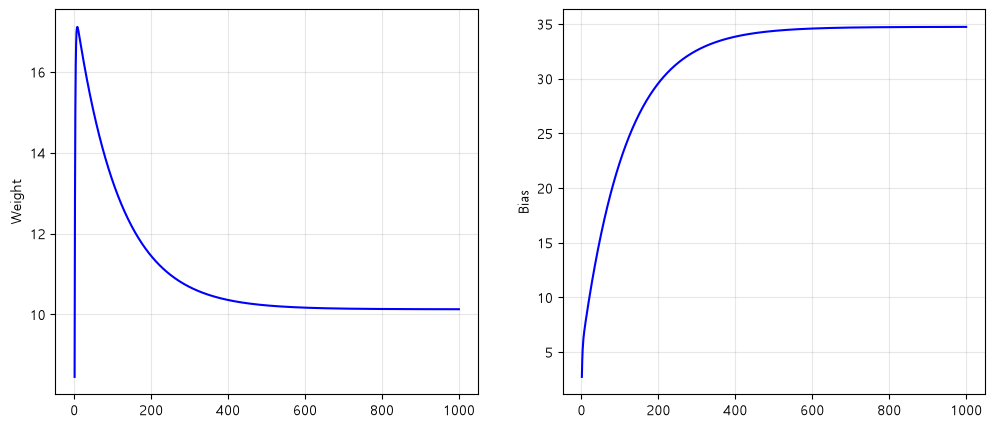

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 기울기 변화
axes[0].plot(
    history_df["epoch"],
    history_df["weight"],
    color="blue"
)
axes[0].grid(alpha=0.3)
axes[0].set_ylabel("Weight")

# 절편 변화
axes[1].plot(
    history_df["epoch"],
        history_df["bias"],
        color="blue"
)
axes[1].grid(alpha=0.3)
axes[1].set_ylabel("Bias")

plt.show()